# Laboratorio 10 - Deep Learning

- Juan Diego Solís Martínez - 23720
- Victor Manuel Pérez Chávez - 23731
- Diego Oswaldo Flores Rivas - 23714

## Task 3

In [1]:
# !pip install shap
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import warnings
warnings.filterwarnings("ignore")
from scipy.stats import spearmanr, rankdata
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier

SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 160)
print("Semilla aleatoria:", SEED)

Semilla aleatoria: 42


Se reconstruyen el modelo del Task 2.1 y los valores SHAP del Task 2.2 con el mismo código y semilla, para trabajar sobre los mismos clientes.

In [2]:
datos = fetch_openml("credit-g", version=1, as_frame=True)
X_raw = datos.data.copy()
y = (datos.target == "good").astype(int)

cat_cols = X_raw.select_dtypes(include=["category", "object"]).columns.tolist()
num_cols = [c for c in X_raw.columns if c not in cat_cols]
enc = OrdinalEncoder()
X = X_raw.copy()
X[cat_cols] = enc.fit_transform(X_raw[cat_cols])
X = X.astype(float)
cols, d = X.columns, X.shape[1]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
modelo = GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=SEED).fit(X_train, y_train)
p_test = modelo.predict_proba(X_test)[:, 1]

rng = np.random.default_rng(SEED)
fondo = X_train.iloc[rng.choice(len(X_train), 100, replace=False)]
explicador = shap.TreeExplainer(modelo, data=fondo, feature_perturbation="interventional", model_output="raw")
phi = explicador.shap_values(X_test)

# Clientes: aprobado y rechazado del Task 2.2, y el más cercano a p = 0.5
i_bueno, i_malo = int(np.argmax(p_test)), int(np.argmin(p_test))
i_medio = int(np.argmin(np.abs(p_test - 0.5)))
clientes = {"Aprobado": i_bueno, "Rechazado": i_malo, "Indeciso": i_medio}
assert p_test[i_bueno] > 0.8 and p_test[i_malo] < 0.2 and 0.45 < p_test[i_medio] < 0.55
for n, i in clientes.items():
    print(f"{n:10s} posición {i:3d} (índice original {X_test.index[i]}), p(good) = {p_test[i]:.4f}")

Aprobado   posición  50 (índice original 175), p(good) = 0.9994
Rechazado  posición  76 (índice original 721), p(good) = 0.0517
Indeciso   posición  87 (índice original 164), p(good) = 0.5040


### Task 3.1

LIME desde cero. Cada variable está presente (valor de la instancia) o ausente (valor al azar de su columna en entrenamiento). El peso es $\pi_x(z) = \exp(-D^2/\sigma^2)$ con $D^2$ el número de ausentes y $\sigma = \sigma_{rel}\sqrt{d'}$. La regresión ridge ponderada se resuelve en forma cerrada con una columna de unos; el intercepto no se penaliza (su entrada en $\lambda I$ es cero), para que la regularización solo encoja los coeficientes de las variables.

In [3]:
Xtr = X_train.values

def ajuste_ponderado(Zb, yv, pi, lam):
    A = np.column_stack([np.ones(len(Zb)), Zb])
    R = lam * np.eye(A.shape[1])
    R[0, 0] = 0                                   # intercepto sin penalizar
    AtP = A.T * pi
    w = np.linalg.solve(AtP @ A + R, AtP @ yv)    # w = (Z'^T Pi Z' + lambda I)^-1 Z'^T Pi y
    g = A @ w
    y_w = (pi * yv).sum() / pi.sum()
    r2 = 1 - (pi * (yv - g) ** 2).sum() / (pi * (yv - y_w) ** 2).sum()   # R^2_w
    return w, r2

def lime(x, N=5000, K=5, lam=1.0, sigma_rel=0.75, seed=SEED, salida=None):
    salida = salida or (lambda D: modelo.predict_proba(D)[:, 1])   # probabilidad de good
    rng = np.random.default_rng(seed)
    Zb = (rng.random((N, d)) < 0.5).astype(float)                   # z' ~ Bernoulli(0.5)
    filas = rng.integers(0, len(Xtr), size=(N, d))
    Z = np.where(Zb == 1, x, Xtr[filas, np.arange(d)])              # ausente: valor al azar de la columna
    yv = salida(pd.DataFrame(Z, columns=cols))
    D2 = d - Zb.sum(1)
    pi = np.exp(-D2 / (sigma_rel * np.sqrt(d)) ** 2)
    w20, r2_20 = ajuste_ponderado(Zb, yv, pi, lam)
    top = np.argsort(-np.abs(w20[1:]))[:K]                          # K variables de mayor |w|
    wK, r2K = ajuste_ponderado(Zb[:, top], yv, pi, lam)
    return {"w20": w20[1:], "top": top, "wK": wK[1:], "b": wK[0], "r2": r2K, "r2_20": r2_20,
            "nef": pi.sum() ** 2 / (pi ** 2).sum()}

In [4]:
res_lime = {}
for n, i in clientes.items():
    r = res_lime[n] = lime(X_test.values[i])
    print(f"{n} (p(good) = {p_test[i]:.4f})   R2_w = {r['r2']:.4f}   intercepto = {r['b']:.4f}")
    for j, w in zip(r["top"], r["wK"]):
        print(f"   {cols[j]:25s} valor = {X_raw.loc[X_test.index[i], cols[j]]!s:22s} w = {w:+.4f}")

Aprobado (p(good) = 0.9994)   R2_w = 0.2426   intercepto = 0.7106
   purpose                   valor = used car               w = +0.1033
   residence_since           valor = 1                      w = +0.0733
   age                       valor = 53                     w = +0.0685
   checking_status           valor = no checking            w = +0.0567
   savings_status            valor = no known savings       w = +0.0537
Rechazado (p(good) = 0.0517)   R2_w = 0.2994   intercepto = 0.4912
   credit_history            valor = all paid               w = -0.1986
   credit_amount             valor = 433                    w = -0.1544
   duration                  valor = 6                      w = +0.1336
   savings_status            valor = >=1000                 w = +0.1203
   other_payment_plans       valor = bank                   w = -0.1175
Indeciso (p(good) = 0.5040)   R2_w = 0.2791   intercepto = 0.6351
   checking_status           valor = no checking            w = +0.2408
   durati

### Task 3.2

Estabilidad en el cliente rechazado: 20 corridas por combinación de $N$ y $\sigma_{rel}$ (semillas 42 a 61, las mismas en cada combinación), Jaccard promedio entre los 190 pares de conjuntos top-5 y $N_{ef}$ promedio.

In [5]:
x_malo = X_test.values[i_malo]
semillas = [SEED + r for r in range(20)]
jaccard = lambda A, B: len(A & B) / len(A | B)    # J(A, B) = |A n B| / |A u B|

def estabilidad(N, sigma_rel, K=5):
    corridas = [lime(x_malo, N=N, K=K, sigma_rel=sigma_rel, seed=s) for s in semillas]
    conjuntos = [set(r["top"]) for r in corridas]
    J = np.mean([jaccard(A, B) for A, B in combinations(conjuntos, 2)])
    return J, np.mean([r["nef"] for r in corridas])    # N_ef = (sum pi)^2 / sum pi^2

Ns, sigmas = [500, 2000, 5000], [0.5, 0.75, 1.5]
est = {(N, s): estabilidad(N, s) for N in Ns for s in sigmas}
tabla_J = pd.DataFrame([[est[N, s][0] for s in sigmas] for N in Ns], index=pd.Index(Ns, name="N"),
                       columns=[f"sigma_rel={s}" for s in sigmas])
tabla_nef = pd.DataFrame([[est[N, s][1] for s in sigmas] for N in Ns], index=tabla_J.index, columns=tabla_J.columns)
print("Jaccard promedio:")
print(tabla_J.round(3).to_string())
print("\nN_ef promedio:")
print(tabla_nef.round(1).to_string())
print("\nN_ef / N:")
print(tabla_nef.div(Ns, axis=0).round(3).to_string())

Jaccard promedio:
      sigma_rel=0.5  sigma_rel=0.75  sigma_rel=1.5
N                                                 
500           0.793           0.816          0.791
2000          0.937           0.937          0.937
5000          1.000           1.000          1.000

N_ef promedio:
      sigma_rel=0.5  sigma_rel=0.75  sigma_rel=1.5
N                                                 
500           409.7           480.5          498.8
2000         1639.4          1922.5         1995.1
5000         4099.9          4806.3         4987.6

N_ef / N:
      sigma_rel=0.5  sigma_rel=0.75  sigma_rel=1.5
N                                                 
500           0.819           0.961          0.998
2000          0.820           0.961          0.998
5000          0.820           0.961          0.998


### Task 3.3

a. Spearman entre $|w|$ de LIME (20 variables) y $|\phi|$ de SHAP, y coincidencia de las tres variables principales.

In [6]:
filas = []
for n, i in clientes.items():
    w20 = res_lime[n]["w20"]
    rho = spearmanr(np.abs(w20), np.abs(phi[i]))[0]
    t_lime = [cols[j] for j in np.argsort(-np.abs(w20))[:3]]
    t_shap = [cols[j] for j in np.argsort(-np.abs(phi[i]))[:3]]
    filas.append([n, rho, ", ".join(t_lime), ", ".join(t_shap), len(set(t_lime) & set(t_shap))])
tabla_ls = pd.DataFrame(filas, columns=["Cliente", "Spearman", "Top-3 LIME", "Top-3 SHAP", "Coincidencias"])
print(tabla_ls.round(3).to_string(index=False))

  Cliente  Spearman                               Top-3 LIME                                    Top-3 SHAP  Coincidencias
 Aprobado     0.737            purpose, residence_since, age                 purpose, age, checking_status              2
Rechazado     0.952  credit_history, credit_amount, duration credit_history, savings_status, credit_amount              2
 Indeciso     0.869 checking_status, duration, credit_amount      checking_status, duration, credit_amount              3


b. $R^2_w$ del cliente rechazado según $K$ (misma semilla, por lo que todas las corridas usan las mismas muestras).

In [7]:
tabla_K = pd.DataFrame({"K": [3, 5, 10, 20]})
tabla_K["R2_w"] = [lime(x_malo, K=K)["r2"] for K in tabla_K["K"]]
print(tabla_K.round(4).to_string(index=False))

 K   R2_w
 3 0.2228
 5 0.2994
10 0.3630
20 0.3718


### Task 3.4

Contrafactuales del cliente rechazado por muestreo: 20 000 candidatos que cambian entre 1 y 3 variables accionables con valores observados en entrenamiento. Para que cada variable elegida cambie de verdad, el valor nuevo se toma entre las filas de entrenamiento cuyo valor difiere del original, lo que conserva la distribución empírica. La distancia usa el MAD en las numéricas y una indicadora en las categóricas.

In [8]:
accionables = ["duration", "credit_amount", "installment_commitment", "checking_status", "savings_status"]
j_acc = [cols.get_loc(c) for c in accionables]
es_num = np.array([c in num_cols for c in cols])

mad = np.median(np.abs(Xtr - np.median(Xtr, axis=0)), axis=0)
mad_media = np.mean(np.abs(Xtr - Xtr.mean(axis=0)), axis=0)
escala = np.where(mad > 0, mad, mad_media)        # MAD_j, o desviación absoluta media si es cero
print("Escala de la distancia:", {c: round(float(escala[cols.get_loc(c)]), 3) for c in accionables if c in num_cols})

def decodificar(col, v):
    return enc.categories_[cat_cols.index(col)][int(v)] if col in cat_cols else int(v)

def distancia(C, x):
    return (np.abs(C - x) / escala * es_num).sum(1) + ((C != x) & ~es_num).sum(1)   # d(x, x')

def buscar_contrafactuales(x, n=20000, max_cambios=3, theta=0.5, seed=SEED):
    rng = np.random.default_rng(seed)
    observados = {j: Xtr[:, j][Xtr[:, j] != x[j]] for j in j_acc}
    C = np.tile(x, (n, 1))
    for m in range(n):
        for j in rng.choice(j_acc, rng.integers(1, max_cambios + 1), replace=False):
            C[m, j] = rng.choice(observados[j])
    p = modelo.predict_proba(pd.DataFrame(C, columns=cols))[:, 1]
    return C, p, distancia(C, x), C != x, p >= theta

max_cambios = 3
C, p_cf, dist, cambio, valido = buscar_contrafactuales(x_malo, max_cambios=max_cambios)
if not valido.any():
    max_cambios = 5
    C, p_cf, dist, cambio, valido = buscar_contrafactuales(x_malo, max_cambios=max_cambios)
print(f"Máximo de variables cambiadas: {max_cambios}")

# El de menor distancia y luego los siguientes con conjunto de variables cambiadas distinto
elegidos, conjuntos = [], []
for m in np.argsort(np.where(valido, dist, np.inf)):
    if not valido[m] or len(elegidos) == 3:
        break
    s = frozenset(np.where(cambio[m])[0])
    if s not in conjuntos:
        elegidos.append(m)
        conjuntos.append(s)

filas = []
for r, m in enumerate(elegidos, 1):
    for j in np.where(cambio[m])[0]:
        filas.append([r, cols[j], decodificar(cols[j], x_malo[j]), decodificar(cols[j], C[m, j]), dist[m], p_cf[m]])
tabla_cf = pd.DataFrame(filas, columns=["CF", "Variable", "Original", "Nuevo", "Distancia", "p(good)"])
print(f"p(good) original: {p_test[i_malo]:.4f}\n")
print(tabla_cf.round(4).to_string(index=False))

print(f"\nValidez: {valido.mean():.4f} ({valido.sum()} de {len(valido)} candidatos)")
print(f"Proximidad promedio: {dist[elegidos].mean():.3f} en los 3 elegidos, {dist[valido].mean():.3f} en todos los válidos")
print(f"Dispersión promedio: {cambio[elegidos].sum(1).mean():.2f} en los 3 elegidos, {cambio[valido].sum(1).mean():.2f} en todos los válidos")

Escala de la distancia: {'duration': 6.0, 'credit_amount': 1057.5, 'installment_commitment': 1.0}


Máximo de variables cambiadas: 3
p(good) original: 0.0517

 CF               Variable Original       Nuevo  Distancia  p(good)
  1        checking_status 0<=X<200 no checking     1.0199   0.5959
  1          credit_amount      433         454     1.0199   0.5959
  2        checking_status 0<=X<200 no checking     2.0047   0.6747
  2          credit_amount      433         428     2.0047   0.6747
  2 installment_commitment        4           3     2.0047   0.6747
  3          credit_amount      433         426     2.0066   0.5836
  3 installment_commitment        4           2     2.0066   0.5836

Validez: 0.0087 (174 de 20000 candidatos)
Proximidad promedio: 1.677 en los 3 elegidos, 3.790 en todos los válidos
Dispersión promedio: 2.33 en los 3 elegidos, 2.83 en todos los válidos


### Task 3.5

Esta sección es de análisis: aquí solo se calculan los números que se usan en las respuestas del documento.

a. Relación entre $N_{ef}$ y el Jaccard, y número de muestras para un Jaccard de 0.9 con $\sigma_{rel} = 0.75$. Se ajusta una ley de potencia $1 - J = a N^b$ con los puntos donde $J < 1$ (el error de los coeficientes de una regresión decrece como una potencia del tamaño efectivo de muestra) y se verifica con una corrida adicional en el $N$ estimado.

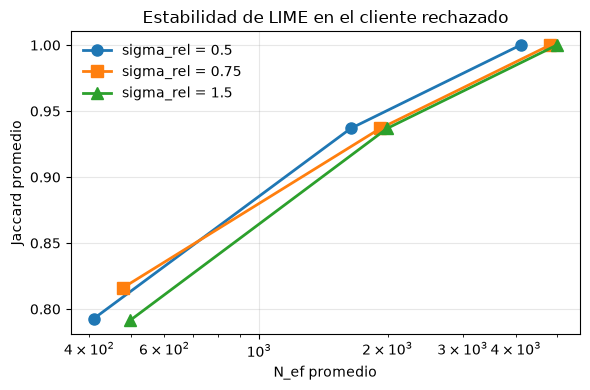

Ajuste 1 - J = 22.022 N^(-0.770) con N = [500, 2000]
N estimado para J = 0.9: 1200
   Verificación N =  1200: Jaccard = 0.878, N_ef = 1153.4


   Verificación N =  1500: Jaccard = 0.911, N_ef = 1441.9
   Verificación N =  1800: Jaccard = 0.967, N_ef = 1730.4


In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
for s, marca in zip(sigmas, ["o", "s", "^"]):
    ax.plot([est[N, s][1] for N in Ns], [est[N, s][0] for N in Ns], marker=marca, lw=2, ms=8, label=f"sigma_rel = {s}")
ax.set_xscale("log"); ax.set_xlabel("N_ef promedio"); ax.set_ylabel("Jaccard promedio")
ax.grid(alpha=0.3); ax.legend(frameon=False); ax.set_title("Estabilidad de LIME en el cliente rechazado")
plt.tight_layout(); plt.show()

pts = [(N, est[N, 0.75][0]) for N in Ns if est[N, 0.75][0] < 1]
b, log_a = np.polyfit(np.log([N for N, _ in pts]), np.log([1 - J for _, J in pts]), 1)
N_09 = int(np.ceil(np.exp((np.log(0.1) - log_a) / b) / 100) * 100)
print(f"Ajuste 1 - J = {np.exp(log_a):.3f} N^({b:.3f}) con N = {[N for N, _ in pts]}")
print(f"N estimado para J = 0.9: {N_09}")
for N in [N_09, N_09 + 300, N_09 + 600]:
    J, nef = estabilidad(N, 0.75)
    print(f"   Verificación N = {N:5d}: Jaccard = {J:.3f}, N_ef = {nef:.1f}")

b. Cliente y variable con mayor discrepancia entre LIME y SHAP, medida como la diferencia de posición entre los rankings de $|w|$ y $|\phi|$. Luego se prueban tres hipótesis: localidad (reducir $\sigma_{rel}$), no linealidad de la sigmoide (explicar el log-odds en lugar de la probabilidad) y el efecto de cambiar solo esa variable.

In [10]:
filas = []
for n, i in clientes.items():
    rl, rs = rankdata(-np.abs(res_lime[n]["w20"])), rankdata(-np.abs(phi[i]))
    for j in range(d):
        filas.append([n, cols[j], res_lime[n]["w20"][j], phi[i, j], rl[j], rs[j], abs(rl[j] - rs[j])])
disc = pd.DataFrame(filas, columns=["Cliente", "Variable", "w LIME", "phi SHAP", "Rank LIME", "Rank SHAP", "Diferencia"])
print(disc.sort_values("Diferencia", ascending=False).head(5).round(4).to_string(index=False))

cli, var = disc.loc[disc["Diferencia"].idxmax(), ["Cliente", "Variable"]]
i_d, j_d = clientes[cli], cols.get_loc(var)
x_d = X_test.values[i_d]
print(f"\nMayor discrepancia: cliente {cli}, variable {var} (valor {X_raw.loc[X_test.index[i_d], var]})")

filas = []
for nombre, sal in [("probabilidad", None), ("log-odds", modelo.decision_function)]:
    for s in [0.25, 0.5, 0.75, 1.5]:
        r = lime(x_d, sigma_rel=s, salida=sal)
        filas.append([nombre, s, r["w20"][j_d], rankdata(-np.abs(r["w20"]))[j_d],
                      spearmanr(np.abs(r["w20"]), np.abs(phi[i_d]))[0], r["r2_20"]])
print(pd.DataFrame(filas, columns=["Salida", "sigma_rel", f"w {var}", "Rank", "Spearman con SHAP", "R2_w (20)"]).round(4).to_string(index=False))

 Cliente            Variable  w LIME  phi SHAP  Rank LIME  Rank SHAP  Diferencia
Aprobado other_payment_plans -0.0006    0.2301       18.0        8.0        10.0
Aprobado       other_parties -0.0001   -0.0636       20.0       11.0         9.0
Aprobado      num_dependents -0.0047   -0.0028       13.0       20.0         7.0
Indeciso     residence_since -0.0139   -0.0119       11.0       18.0         7.0
Indeciso    existing_credits -0.0109   -0.1185       14.0        8.0         6.0

Mayor discrepancia: cliente Aprobado, variable other_payment_plans (valor bank)


      Salida  sigma_rel  w other_payment_plans  Rank  Spearman con SHAP  R2_w (20)
probabilidad       0.25                 0.0066   9.0             0.8391     0.2423
probabilidad       0.50                 0.0016  15.0             0.7820     0.2688
probabilidad       0.75                -0.0006  18.0             0.7368     0.2650
probabilidad       1.50                -0.0022  17.0             0.7278     0.2623
    log-odds       0.25                 0.3130   7.0             0.8872     0.4844
    log-odds       0.50                 0.2768   8.0             0.8571     0.4419
    log-odds       0.75                 0.2358   8.0             0.8391     0.4225
    log-odds       1.50                 0.2103   8.0             0.8602     0.4114


        p(good)  log-odds
bank     0.9994    7.4990
none     0.9978    6.1396
stores   0.9985    6.5232


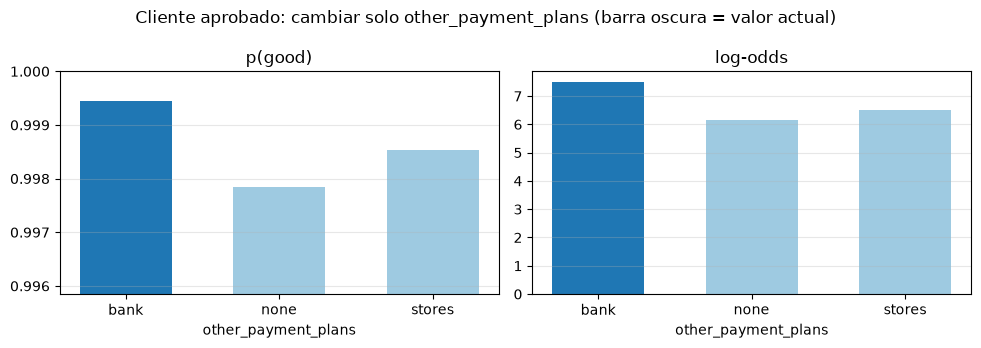

In [11]:
# Cambiar solo esa variable en el cliente, en probabilidad y en log-odds
valores = np.unique(Xtr[:, j_d])
Zv = np.tile(x_d, (len(valores), 1)); Zv[:, j_d] = valores
Zv = pd.DataFrame(Zv, columns=cols)
p_v, f_v = modelo.predict_proba(Zv)[:, 1], modelo.decision_function(Zv)
etiquetas = [str(decodificar(var, v)) for v in valores]
print(pd.DataFrame({"p(good)": p_v, "log-odds": f_v}, index=etiquetas).round(4).to_string())

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
color = ["#1f77b4" if v == x_d[j_d] else "#9ecae1" for v in valores]
ax[0].bar(etiquetas, p_v, color=color, width=0.6); ax[0].set_ylim(p_v.min() - 0.002, 1); ax[0].set_title("p(good)")
ax[1].bar(etiquetas, f_v, color=color, width=0.6); ax[1].set_title("log-odds")
for a in ax:
    a.grid(axis="y", alpha=0.3); a.set_xlabel(var)
fig.suptitle(f"Cliente {cli.lower()}: cambiar solo {var} (barra oscura = valor actual)")
plt.tight_layout(); plt.show()

c. La tabla de $R^2_w$ según $K$ está en el Task 3.3 b.

d. Variables de los contrafactuales frente a las tres de mayor $|\phi|$ del cliente rechazado, y efecto de cambiar una sola variable accionable a cada valor observado.

In [12]:
top3 = np.argsort(-np.abs(phi[i_malo]))[:3]
inmutables = ["age", "personal_status", "foreign_worker"]
en_cf = {cols[j] for s in conjuntos for j in s}
print("Variables en los contrafactuales:", sorted(en_cf))
for j in top3:
    tipo = "inmutable" if cols[j] in inmutables else "accionable" if cols[j] in accionables else "no accionable"
    print(f"   {cols[j]:18s} phi = {phi[i_malo, j]:+.4f}  valor = {decodificar(cols[j], x_malo[j])!s:12s} {tipo}, en CF: {cols[j] in en_cf}")

# Mejor resultado posible cambiando una sola variable
filas = []
for c in accionables + [cols[j] for j in top3 if cols[j] not in accionables]:
    j = cols.get_loc(c)
    vals = np.unique(Xtr[:, j]); vals = vals[vals != x_malo[j]]
    Zc = np.tile(x_malo, (len(vals), 1)); Zc[:, j] = vals
    pc, dc = modelo.predict_proba(pd.DataFrame(Zc, columns=cols))[:, 1], distancia(Zc, x_malo)
    k = np.argmax(pc)
    ok = pc >= 0.5
    filas.append([c, decodificar(c, x_malo[j]), decodificar(c, vals[k]), pc[k], dc[k], dc[ok].min() if ok.any() else np.nan])
print(pd.DataFrame(filas, columns=["Variable", "Original", "Mejor valor", "p(good) máx", "Distancia", "Distancia mín. con p >= 0.5"])
      .round(4).to_string(index=False))

Variables en los contrafactuales: ['checking_status', 'credit_amount', 'installment_commitment']
   credit_history     phi = -1.3162  valor = all paid     no accionable, en CF: False
   savings_status     phi = +0.9721  valor = >=1000       accionable, en CF: False
   credit_amount      phi = -0.9647  valor = 433          accionable, en CF: True
              Variable Original                    Mejor valor  p(good) máx  Distancia  Distancia mín. con p >= 0.5
              duration        6                              4       0.0517     0.3333                          NaN
         credit_amount      433                            250       0.4564     0.1730                          NaN
installment_commitment        4                              2       0.0978     2.0000                          NaN
       checking_status 0<=X<200                    no checking       0.1853     1.0000                          NaN
        savings_status   >=1000               no known savings       0.0